# 03 - Analysis
**Project:** E-commerce Sales Dashboard | **Team:** Nehdi Hamza, Snoussi Wadia

This notebook answers the three business questions of the cahier des charges, plus the two secondary analyses:

1. Which products sell best?
2. Which months have the highest revenue?
3. Which customers spend the most?
4. (Bonus) Revenue by country
5. (Bonus) Revenue by day of the week

Every analysis follows the same pattern: **group the rows, calculate something, sort**. Run the notebook from top to bottom (*Restart and Run All*) before you commit.

## 0. Load the cleaned data

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Read the clean file produced by 02_cleaning.ipynb.
# StockCode and InvoiceNo are read as text so codes like 85123A stay intact.
df_clean = pd.read_csv(
    "../data/cleanData.csv",
    dtype={"InvoiceNo": str, "StockCode": str, "CustomerID": str},
    parse_dates=["InvoiceDate"],
)

# Safety check: the cleaning notebook must have removed every row without a CustomerID
assert df_clean["CustomerID"].notna().all(), "Missing CustomerID found: rerun 02_cleaning.ipynb"

# The CSV only holds df_clean, so we rebuild the product table here
products_only = df_clean[df_clean["StockCode"].str.match(r"^\d{5}")]         # real products (no POST, DOT, M...)

print("All valid sales  :", len(df_clean))
print("Real products    :", len(products_only))

# Folders for the charts (report) and the result tables
os.makedirs("../report/figures", exist_ok=True)
os.makedirs("../data/outputs", exist_ok=True)

All valid sales  : 392690
Real products    : 391148


## 1. Key figures (KPIs)

These are the four KPI cards of the dashboard. **Compute them here first**, then check that Power BI shows the same numbers. That is how you prove the dashboard is correct.

- Total revenue: sum of `Revenue`
- Number of orders: number of **different** `InvoiceNo`
- Number of customers: number of **different** `CustomerID`
- Average order value: total revenue / number of orders

In [2]:
total_revenue = df_clean["Revenue"].sum()
n_orders = df_clean["InvoiceNo"].nunique()           # nunique = number of distinct values
n_customers = df_clean["CustomerID"].nunique()       # nunique ignores missing values
avg_order_value = total_revenue / n_orders

print(f"Total revenue       : {total_revenue:,.2f}")
print(f"Number of orders    : {n_orders:,}")
print(f"Number of customers : {n_customers:,}")
print(f"Average order value : {avg_order_value:,.2f}")

kpis = pd.DataFrame({
    "KPI": ["Total revenue", "Number of orders", "Number of customers", "Average order value"],
    "Value": [round(total_revenue, 2), n_orders, n_customers, round(avg_order_value, 2)],
})
kpis.to_csv("../data/outputs/kpis.csv", index=False)
kpis

Total revenue       : 8,641,555.69
Number of orders    : 18,530
Number of customers : 4,337
Average order value : 466.35


,KPI,Value
0,Total revenue,8641555.69
1,Number of orders,18530.00
2,Number of customers,4337.00
3,Average order value,466.35


## 2. Question 1: Which products sell best?

"Sells best" can mean two things: the products that **earn the most money** (Revenue) or the ones that **sell the most units** (Quantity). We compute both and compare.

We use `products_only` so postage and fee codes (POST, DOT, M...) do not appear in the ranking.

In [3]:
# Both measures side by side: one row per product, two columns
product_summary = products_only.groupby("Description")[["Revenue", "Quantity"]].sum()

top10_revenue = product_summary.sort_values("Revenue", ascending=False).head(10)
top10_quantity = product_summary.sort_values("Quantity", ascending=False).head(10)

print("TOP 10 BY REVENUE")
display(top10_revenue)
print("TOP 10 BY QUANTITY")
display(top10_quantity)

# How many products appear in both lists?
common = set(top10_revenue.index) & set(top10_quantity.index)
print(f"Products in both top 10 lists: {len(common)}")

TOP 10 BY REVENUE


,Revenue,Quantity
Description,,
REGENCY CAKESTAND 3 TIER,142264.75,12374
WHITE HANGING HEART T-LIGHT HOLDER,100392.10,36706
JUMBO BAG RED RETROSPOT,85040.54,46078
PARTY BUNTING,68785.23,15279
ASSORTED COLOUR BIRD ORNAMENT,56413.03,35263
RABBIT NIGHT LIGHT,51251.24,27153
CHILLI LIGHTS,46265.11,9646
PAPER CHAIN KIT 50'S CHRISTMAS,42584.13,15591
PICNIC BASKET WICKER 60 PIECES,39619.50,61


TOP 10 BY QUANTITY


,Revenue,Quantity
Description,,
WORLD WAR 2 GLIDERS ASSTD DESIGNS,13558.41,54319
JUMBO BAG RED RETROSPOT,85040.54,46078
WHITE HANGING HEART T-LIGHT HOLDER,100392.10,36706
ASSORTED COLOUR BIRD ORNAMENT,56413.03,35263
PACK OF 72 RETROSPOT CAKE CASES,16381.88,33670
POPCORN HOLDER,23417.51,30919
RABBIT NIGHT LIGHT,51251.24,27153
MINI PAINT SET VINTAGE,16039.24,26076
PACK OF 12 LONDON TISSUES,7261.77,25329


Products in both top 10 lists: 4


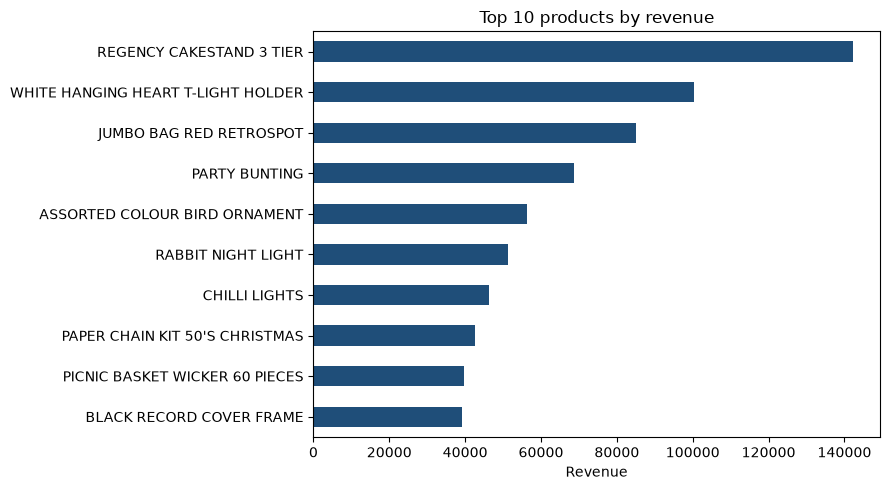

In [4]:
# Chart: top 10 products by revenue (horizontal bars, biggest on top)
fig, ax = plt.subplots(figsize=(9, 5))
top10_revenue["Revenue"].sort_values().plot(kind="barh", ax=ax, color="#1F4E79")
ax.set_title("Top 10 products by revenue")
ax.set_xlabel("Revenue")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../report/figures/top10_products_revenue.png", dpi=150)
plt.show()

top10_revenue.to_csv("../data/outputs/top10_products_revenue.csv")
top10_quantity.to_csv("../data/outputs/top10_products_quantity.csv")

**Check for outliers.** If one single order makes up most of a product's total, the ranking can be misleading. Look at the biggest orders of your number 1 product.

In [5]:
best_product = top10_revenue.index[0]
print("Best product by revenue:", best_product)

(products_only[products_only["Description"] == best_product]
    .sort_values("Quantity", ascending=False)
    [["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice", "Revenue", "Country"]]
    .head(5))

Best product by revenue: REGENCY CAKESTAND 3 TIER


,InvoiceNo,InvoiceDate,Quantity,UnitPrice,Revenue,Country
14385,538191,2010-12-10 10:49:00,272,10.95,2978.4,United Kingdom
194525,561633,2011-07-28 14:33:00,192,10.95,2102.4,United Kingdom
34770,541220,2011-01-14 14:11:00,160,10.95,1752.0,EIRE
67543,545341,2011-03-02 09:03:00,150,10.95,1642.5,United Kingdom
113947,551259,2011-04-27 12:04:00,150,10.95,1642.5,United Kingdom


**Your conclusion for question 1** *(write it in your own words, with numbers from the outputs above)*:

- Best product by revenue: ...
- Best product by quantity: ...
- Which measure will you use in the dashboard, and why: ...

## 3. Question 2: Which months have the highest revenue?

**Warning:** December 2011 is incomplete (data stops on 9 December). Its low value is **not** a drop in sales, so we mark it clearly.

In [6]:
revenue_by_month = df_clean.groupby("Month")["Revenue"].sum()      # Month is "YYYY-MM", so it sorts in time order
print(revenue_by_month.round(2))

best_months = revenue_by_month.sort_values(ascending=False).head(3)
print("\nTop 3 months:")
print(best_months.round(2))

Month
2010-12     570422.73
2011-01     490917.71
2011-02     446084.92
2011-03     594081.76
2011-04     468374.33
2011-05     677355.15
2011-06     660046.05
2011-07     598962.90
2011-08     644051.04
2011-09     950690.20
2011-10    1035642.45
2011-11    1156205.61
2011-12     348720.84
Name: Revenue, dtype: float64

Top 3 months:
Month
2011-11    1156205.61
2011-10    1035642.45
2011-09     950690.20
Name: Revenue, dtype: float64


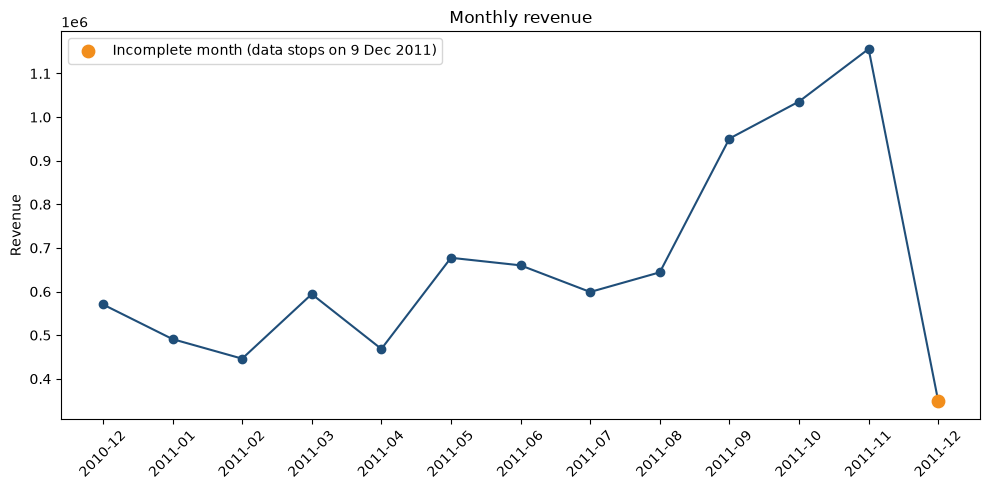

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(revenue_by_month.index, revenue_by_month.values, marker="o", color="#1F4E79")

# Mark the incomplete last month in orange
ax.scatter(revenue_by_month.index[-1], revenue_by_month.values[-1], color="#F28E1C", zorder=3, s=80,
           label="Incomplete month (data stops on 9 Dec 2011)")

ax.set_title("Monthly revenue")
ax.set_ylabel("Revenue")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../report/figures/monthly_revenue.png", dpi=150)
plt.show()

revenue_by_month.to_csv("../data/outputs/monthly_revenue.csv")

**Your conclusion for question 2:**

- Highest months: ...
- Is there a seasonal pattern (for example a rise at the end of the year)? ...
- What does it mean for stock and marketing? ...

## 4. Question 3: Which customers spend the most?

Every row of `df_clean` now has a `CustomerID` (rows without one were removed in the cleaning step).

In [8]:
customers = df_clean   # CustomerID is already clean text (for example "17850")

customer_summary = customers.groupby("CustomerID").agg(
    Revenue=("Revenue", "sum"),
    Orders=("InvoiceNo", "nunique"),
    Country=("Country", "first"),
)

top10_customers = customer_summary.sort_values("Revenue", ascending=False).head(10)
display(top10_customers.round(2))

# How concentrated is the revenue?
share_top10 = top10_customers["Revenue"].sum() / customers["Revenue"].sum()
print(f"The top 10 customers make {share_top10:.1%} of total revenue.")

,Revenue,Orders,Country
CustomerID,,,
14646,280206.02,73,Netherlands
18102,259657.30,60,United Kingdom
17450,194390.79,46,United Kingdom
14911,143711.17,201,EIRE
12415,124914.53,21,Australia
14156,117210.08,55,EIRE
17511,91062.38,31,United Kingdom
16029,80850.84,63,United Kingdom
16684,66653.56,28,United Kingdom


The top 10 customers make 16.5% of total revenue.


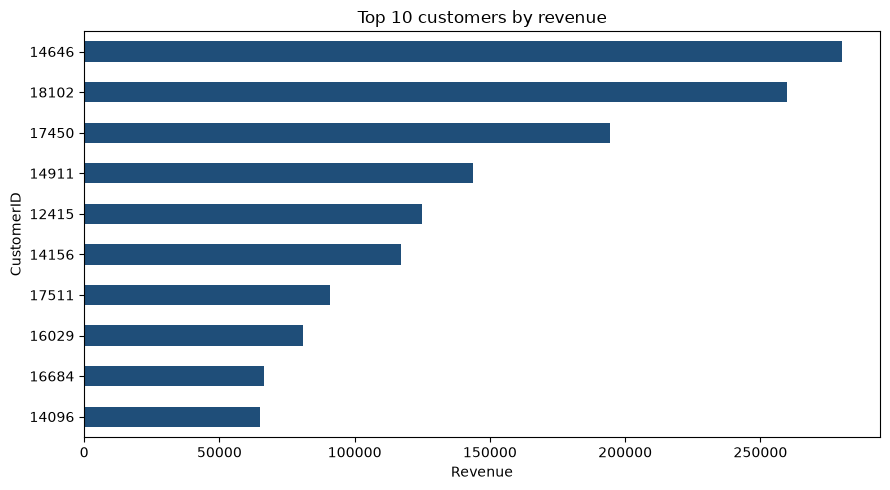

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
top10_customers["Revenue"].sort_values().plot(kind="barh", ax=ax, color="#1F4E79")
ax.set_title("Top 10 customers by revenue")
ax.set_xlabel("Revenue")
ax.set_ylabel("CustomerID")
plt.tight_layout()
plt.savefig("../report/figures/top10_customers.png", dpi=150)
plt.show()

top10_customers.to_csv("../data/outputs/top10_customers.csv")

**Your conclusion for question 3:**

- The top customer is ... and spent ...
- The top 10 customers represent ...% of revenue, so the business depends (a lot / a little) on them.
- Are they mostly from one country? ...

## 5. Bonus: revenue by country

The United Kingdom dominates, so the other countries become invisible on the same chart. We show the top 10 with the UK, then the top 10 without it.

In [10]:
revenue_by_country = df_clean.groupby("Country")["Revenue"].sum().sort_values(ascending=False)

uk_share = revenue_by_country.get("United Kingdom", 0) / revenue_by_country.sum()
print(f"United Kingdom share of revenue: {uk_share:.1%}\n")

print("Top 10 countries:")
print(revenue_by_country.head(10).round(2))

print("\nTop 10 without the United Kingdom:")
top10_no_uk = revenue_by_country.drop("United Kingdom", errors="ignore").head(10)
print(top10_no_uk.round(2))

United Kingdom share of revenue: 81.5%

Top 10 countries:
Country
United Kingdom    7039371.44
Netherlands        285446.34
EIRE               265262.46
Germany            228678.40
France             208934.31
Australia          138453.81
Spain               61558.56
Switzerland         56443.95
Belgium             41196.34
Sweden              38367.83
Name: Revenue, dtype: float64

Top 10 without the United Kingdom:
Country
Netherlands    285446.34
EIRE           265262.46
Germany        228678.40
France         208934.31
Australia      138453.81
Spain           61558.56
Switzerland     56443.95
Belgium         41196.34
Sweden          38367.83
Japan           37416.37
Name: Revenue, dtype: float64


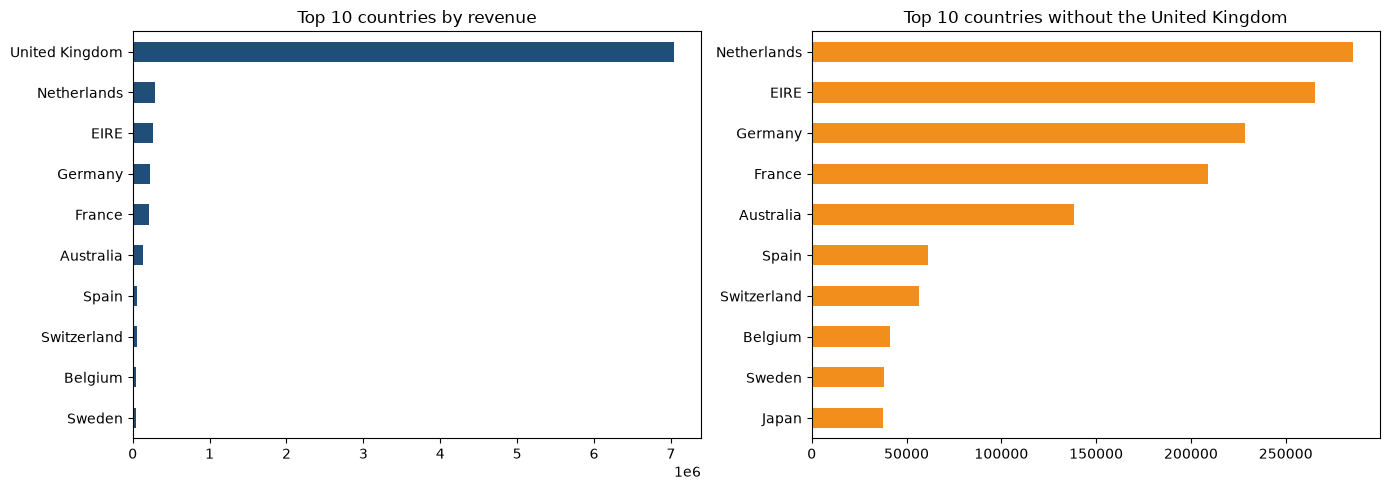

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

revenue_by_country.head(10).sort_values().plot(kind="barh", ax=axes[0], color="#1F4E79")
axes[0].set_title("Top 10 countries by revenue")
axes[0].set_ylabel("")

top10_no_uk.sort_values().plot(kind="barh", ax=axes[1], color="#F28E1C")
axes[1].set_title("Top 10 countries without the United Kingdom")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig("../report/figures/revenue_by_country.png", dpi=150)
plt.show()

revenue_by_country.to_csv("../data/outputs/revenue_by_country.csv")

## 6. Bonus: revenue by day of the week

In [12]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

weekday = df_clean["InvoiceDate"].dt.day_name()
revenue_by_weekday = (df_clean.groupby(weekday)["Revenue"].sum()
                      .reindex(weekday_order, fill_value=0))     # keep days in calendar order, 0 if a day has no sales
print(revenue_by_weekday.round(2))

InvoiceDate
Monday       1363604.40
Tuesday      1620550.20
Wednesday    1584283.83
Thursday     1973015.73
Friday       1314611.21
Saturday           0.00
Sunday        785490.32
Name: Revenue, dtype: float64


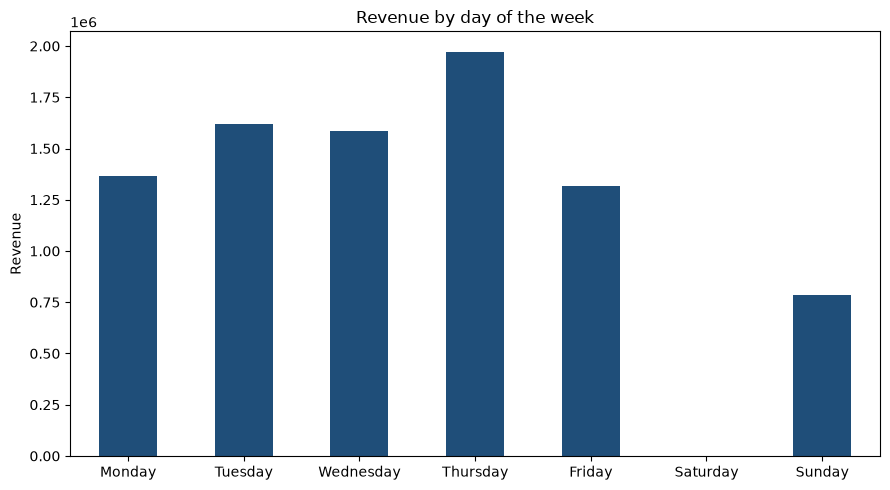

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
revenue_by_weekday.plot(kind="bar", ax=ax, color="#1F4E79")
ax.set_title("Revenue by day of the week")
ax.set_ylabel("Revenue")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../report/figures/revenue_by_weekday.png", dpi=150)
plt.show()

revenue_by_weekday.to_csv("../data/outputs/revenue_by_weekday.csv")

Look at the days with **zero** revenue. If a day has no sales at all, mention it in the report (the shop may simply not process orders that day) instead of treating it as a problem.

## 7. Summary of findings and recommendations

*Fill this in after reading your outputs. The cahier des charges requires **at least 3 actionable recommendations**, and each one must be based on a number you found.*

| # | Finding (with a number) | Recommendation |
|---|-------------------------|----------------|
| 1 | ... | ... |
| 2 | ... | ... |
| 3 | ... | ... |

**Limits to mention in the report**

- December 2011 is incomplete.
- Rows without a CustomerID (about a quarter of the cleaned rows) were removed, as the cahier des charges asks. Total revenue is therefore lower than the revenue of the full dataset.
- Cancelled invoices were removed, so figures are **gross sales** (returns are not subtracted).
- Postage and fee codes count in total revenue but not in the product ranking.